# 4.10 · 01 — Дані: data card, огляд, split protocol
**Проект:** `digits-cnn` — класифікація рукописних цифр 8×8 (Варіант 1 — Image classification).

У цьому ноутбуці: problem contract, data card, перевірка класів і дублікатів, фіксація стратифікованого split train/val/test, який використовують усі наступні ноутбуки.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from src.utils import load_config, set_seed, load_digits_images, SPLIT_PATH

cfg = load_config()
set_seed(cfg["seed"])
X, y = load_digits_images()
print("X:", X.shape, X.dtype, "діапазон", X.min(), "–", X.max(), "| y:", y.shape)

X: (1797, 8, 8) float32 діапазон 0.0 – 1.0 | y: (1797,)


## 1. Problem statement (project contract)
- **Input:** зображення рукописної цифри 8×8 пікселів у відтінках сірого (64 значення інтенсивності 0…1).
- **Target:** клас цифри 0–9 (10 класів).
- **Користувач:** аналітик, що автоматизує розпізнавання рукописних цифр у відсканованих бланках/формулярах (номери, коди, кількості) — типова підзадача обробки паперових документів.
- **Чому DL:** зображення мають просторову структуру (сусідні пікселі пов'язані), CNN використовує її через згортки й має бути стійкішою до зсувів та шуму, ніж лінійна модель на «сирих» пікселях.
- **Success criterion:** macro-F1 на тесті ≥ 0.97 **і** перевага над baseline (логістична регресія) як на чистому тесті, так і за domain shift (шум, зсув на 1 піксель). Якщо CNN не перевершує baseline — висновок «DL не виправдане» також є валідним результатом.

## 2. Data card
| Поле | Значення |
|---|---|
| Джерело | UCI ML *Optical Recognition of Handwritten Digits* (Alpaydin & Kaynak, 1998), вбудовано в scikit-learn: `sklearn.datasets.load_digits` |
| Ліцензія / доступ | відкритий датасет (CC BY 4.0, UCI); інтернет не потрібен |
| Обсяг | 1797 зображень, 10 класів |
| Schema | `X`: 8×8 float32 у [0,1] (оригінал 0–16, поділено на 16); `y`: int 0–9 |
| Labels | розмічено авторами датасету; 43 автори почерку |
| Обмеження | дуже низька роздільність 8×8; лише цифри; відцентровані та нормалізовані за розміром зображення — реальні скани будуть «брудніші» (тому перевіряємо domain shift); інформації про авторів у версії sklearn немає → неможливий split за авторами, можливий leakage через схожий почерк |
| Чутливість | персональних/службових даних немає |

             0    1    2    3    4    5    6    7    8    9
кількість  178  182  177  183  181  182  181  179  174  180


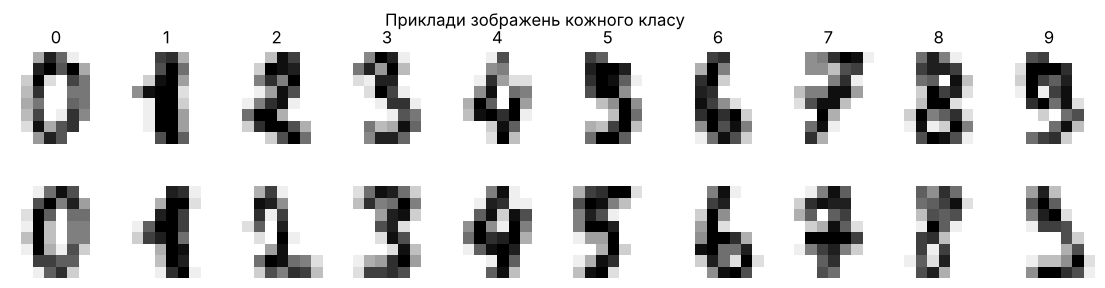

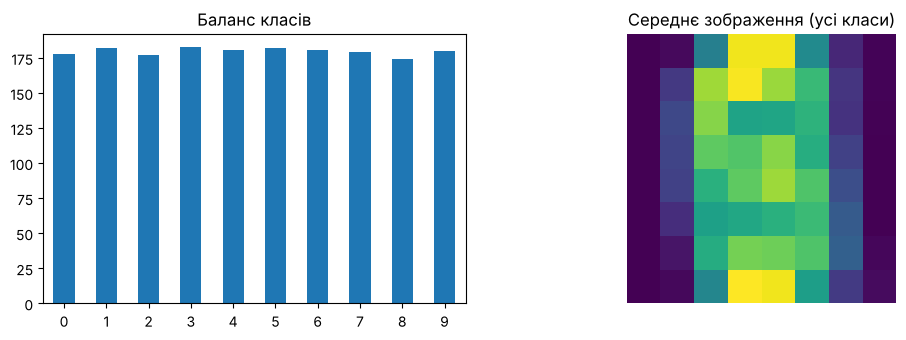

In [2]:
counts = pd.Series(y).value_counts().sort_index()
print(counts.to_frame("кількість").T)

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for d in range(10):
    for r in range(2):
        ax = axes[r, d]
        ax.imshow(X[y == d][r], cmap="gray_r"); ax.axis("off")
        if r == 0: ax.set_title(str(d))
plt.suptitle("Приклади зображень кожного класу"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
counts.plot.bar(ax=axes[0], rot=0, title="Баланс класів")
axes[1].imshow(X.mean(axis=0), cmap="viridis"); axes[1].set_title("Середнє зображення (усі класи)"); axes[1].axis("off")
plt.show()

Класи майже ідеально збалансовані (174–183 зображень), тому accuracy та macro-F1 будуть близькими; основною метрикою беремо **macro-F1**.

## 3. Leakage check: точні дублікати

In [3]:
flat = X.reshape(len(X), -1)
_, inv, cnt = np.unique(flat, axis=0, return_inverse=True, return_counts=True)
n_dup = int((cnt > 1).sum())
print("Груп точних дублікатів:", n_dup)
# Якщо дублікати є — тримаємо всю групу в одній частині split (group-aware), щоб не було leakage
groups = inv.ravel()

Груп точних дублікатів: 0


## 4. Split protocol
- **train 60% / validation 20% / test 20%**, стратифіковано за класом, `seed = 42`.
- **Validation** — для early stopping, вибору гіперпараметрів і вибору фінальної моделі.
- **Test** — використовується **один раз** у `03_dl_experiment.ipynb` після заморожування фінальної конфігурації.
- Індекси зберігаються у `data/splits.npz` — будь-хто відтворить той самий split.

In [4]:
idx = np.arange(len(X))
s = cfg["split"]
idx_trval, idx_test = train_test_split(idx, test_size=s["test_size"], stratify=y, random_state=cfg["seed"])
val_rel = s["val_size"] / (1 - s["test_size"])
idx_train, idx_val = train_test_split(idx_trval, test_size=val_rel, stratify=y[idx_trval], random_state=cfg["seed"])

# Контроль: частини не перетинаються, і дублікати не розкидані між частинами
assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test) or set(idx_val) & set(idx_test))
part_of = np.empty(len(X), dtype=object)
part_of[idx_train], part_of[idx_val], part_of[idx_test] = "train", "val", "test"
leak = [g for g in np.unique(groups) if len(set(part_of[groups == g])) > 1]
print("Груп дублікатів, розкиданих між частинами:", len(leak))

SPLIT_PATH.parent.mkdir(exist_ok=True)
np.savez(SPLIT_PATH, train=idx_train, val=idx_val, test=idx_test)

summary = pd.DataFrame({p: pd.Series(y[i]).value_counts().sort_index() for p, i in
                        [("train", idx_train), ("val", idx_val), ("test", idx_test)]}).T
summary["усього"] = summary.sum(axis=1)
print("Збережено:", SPLIT_PATH.relative_to(Path.cwd().parent))
summary

Груп дублікатів, розкиданих між частинами: 0
Збережено: data/splits.npz


,0,1,2,3,4,5,6,7,8,9,усього
train,106,109,107,109,109,109,109,107,104,108,1077
val,36,37,35,37,36,36,36,36,35,36,360
test,36,36,35,37,36,37,36,36,35,36,360


**Висновок етапу:** дані відкриті й збалансовані, split зафіксовано і перевірено на перетини. Головне відоме обмеження — немає ідентифікаторів авторів, тому оцінка може бути дещо оптимістичною щодо нових почерків; це враховано в limitations.